# Beat travel times (theoretical)

Modelled driving times from each beat center and each police facility to every Oakland address (OSRM, free-flow), compared with observed CAD times and with Mapbox estimates that include historical traffic.

OSRM and Mapbox results load from earlier runs cached in `Outputs/`. Set a `RERUN_*` flag to query the API again; results are kept in memory only.

In [1]:
import re
import time

import numpy as np
import pandas as pd
import geopandas as gpd
import requests
import shapely
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, Normalize
from box_utils import BOX_ROOT

OPD = BOX_ROOT / "OPD & TAN - Core Workspace" / "02 Oakland Police Dept (OPD)"
DATA = OPD / "Data" / "Our Data"
CACHE = OPD / "Outputs"                     # cached OSRM / Mapbox runs (read only)

OSRM = "https://router.project-osrm.org"    # public demo server: ~1 request/s
CHUNK = 350                                 # destinations per table call (URL length limit)
RERUN_OSRM = False
RERUN_FACILITIES = False
RERUN_MAPBOX = False

In [2]:
# 1) Beats (city open data) and beat centers.
#    LKM1 (Lake Merritt) and PDT2 (Piedmont) are not OPD beats; kept only as map labels.
#    Five beats carry stray slivers in the source layer; keep each beat's main polygon.
beats_all = gpd.read_file("https://data.oaklandca.gov/api/geospatial/78s7-673i?method=export&format=GeoJSON")
beats_all = beats_all[["name", "pol_dist", "acres", "geometry"]].rename(columns={"name": "beat", "pol_dist": "area"})
enclaves = beats_all[beats_all["beat"].isin(["LKM1", "PDT2"])].assign(label=["Lake Merritt", "Piedmont"])
beats = beats_all.query("beat not in ['LKM1', 'PDT2']").sort_values("beat").reset_index(drop=True)
beats["geometry"] = beats.geometry.apply(lambda g: max(g.geoms, key=lambda p: p.area) if g.geom_type == "MultiPolygon" else g)

# center = centroid, or a guaranteed-inside point where the centroid falls outside the beat
utm = beats.to_crs(26910).geometry
cen = utm.centroid
inside = cen.within(utm)
cen[~inside] = utm.representative_point()[~inside]
beats["center_lon"] = cen.to_crs(4326).x
beats["center_lat"] = cen.to_crs(4326).y
print(len(beats), "beats")

57 beats


In [3]:
# 2) Address points (Alameda County GIS), assigned to beats; distance to the beat edge in metres.
addresses = pd.read_parquet(DATA / "oakland_address_points.parquet")
addresses = gpd.GeoDataFrame(addresses, geometry=gpd.points_from_xy(addresses["lon"], addresses["lat"]), crs=4326)
addresses = gpd.sjoin(addresses, beats[["beat", "geometry"]], how="inner", predicate="within").drop(columns="index_right")
edges = beats.set_index("beat").to_crs(26910).geometry.boundary
addresses["dist_to_edge_m"] = shapely.distance(addresses.to_crs(26910).geometry.values, edges.loc[addresses["beat"]].values)
print(f"{len(addresses):,} addresses in 57 beats; {(addresses['dist_to_edge_m'] <= 100).sum():,} within 100 m of an edge")

131,923 addresses in 57 beats; 35,283 within 100 m of an edge


In [4]:
# 3) Address density. Low-density beats contain parks, port and rail land, so few points does not mean missing data.
density = (beats[["beat", "acres"]].merge(addresses.groupby("beat").size().rename("n_addresses"), on="beat", how="left")
                                   .fillna({"n_addresses": 0}))
density["addresses_per_acre"] = density["n_addresses"] / pd.to_numeric(density["acres"], errors="coerce")
density.sort_values("addresses_per_acre").head(10)

,beat,acres,n_addresses,addresses_per_acre
48,31X,13616.028,143,0.010502
7,05Y,1866.395,851,0.455959
9,07X,3284.273,2193,0.667728
2,02Y,2092.527,1796,0.858292
40,26X,753.56000000000006,696,0.923616
56,35Y,2689.367,2629,0.977553
39,25Y,1924.476,2334,1.212798
18,13Y,2789.632,4057,1.454314
1,02X,612.34,1323,2.160564
49,31Y,734.246,1603,2.183192


In [5]:
# 4) OSRM table calls: one origin, up to CHUNK destinations per request.
def osrm_minutes(lon, lat, dests):
    coords = ";".join([f"{lon:.6f},{lat:.6f}"] + [f"{x:.6f},{y:.6f}" for x, y in zip(dests["lon"], dests["lat"])])
    r = requests.get(f"{OSRM}/table/v1/driving/{coords}", params={"sources": "0", "annotations": "duration,distance"}, timeout=60)
    r.raise_for_status()
    js = r.json()
    out = dests[["beat", "ADDRESS", "lon", "lat", "dist_to_edge_m"]].copy()
    out["minutes"] = np.array(js["durations"][0][1:], dtype=float) / 60
    out["km"] = np.array(js["distances"][0][1:], dtype=float) / 1000
    return out

def osrm_all(lon, lat, dests):
    parts = []
    for start in range(0, len(dests), CHUNK):
        parts.append(osrm_minutes(lon, lat, dests.iloc[start:start + CHUNK]))
        time.sleep(1.1)
    return pd.concat(parts, ignore_index=True)

# beat center -> every address in that beat
if RERUN_OSRM:
    results = pd.concat([osrm_all(b.center_lon, b.center_lat, addresses[addresses["beat"] == b.beat]) for b in beats.itertuples()],
                        ignore_index=True)
else:
    results = pd.read_parquet(CACHE / "beat_center_to_addresses_times.parquet")
print(f"{len(results):,} beat center -> address times")

131,923 beat center -> address times


In [6]:
# 5) Police facilities -> every address.
facilities = pd.DataFrame([
    {"facility": "PAB", "lon": -122.27475, "lat": 37.79948, "beat": "03Y"},       # Police Administration Building, 455 7th St
    {"facility": "Eastmont", "lon": -122.17545, "lat": 37.76752, "beat": "30Y"},  # Eastmont substation, 2651 73rd Ave
])
if RERUN_FACILITIES:
    facility_results = pd.concat([osrm_all(f.lon, f.lat, addresses).assign(facility=f.facility) for f in facilities.itertuples()],
                                 ignore_index=True)
else:
    facility_results = pd.read_parquet(CACHE / "facility_to_addresses_times.parquet")
facility_summary = (facility_results.groupby(["facility", "beat"])["minutes"]
                    .agg(n="size", median_min="median", p90_min=lambda s: s.quantile(.9), max_min="max").round(1).reset_index())
print(f"{len(facility_results):,} facility -> address times")
facility_summary.head()

263,846 facility -> address times


,facility,beat,n,median_min,p90_min,max_min
0,Eastmont,01X,2627,11.6,12.6,16.5
1,Eastmont,02X,1323,13.7,14.5,18.6
2,Eastmont,02Y,1796,15.0,15.8,22.8
3,Eastmont,03X,2974,12.4,13.0,13.4
4,Eastmont,03Y,849,13.0,13.2,13.9


In [7]:
# 6) Per-beat summary of beat center -> address minutes.
summary = (results.groupby("beat")["minutes"]
                  .agg(n="size", median="median", p90=lambda s: s.quantile(.9), max="max").round(1).reset_index()
                  .merge(beats[["beat", "area", "acres", "center_lon", "center_lat"]], on="beat"))
print("citywide median", summary["median"].median(), "min | longest beat max", summary["max"].max(), "min")
summary.sort_values("max", ascending=False).head(10)

citywide median 1.9 min | longest beat max 24.7 min


,beat,n,median,p90,max,area,acres,center_lon,center_lat
7,05Y,851,13.1,13.8,24.7,1,1866.395,-122.324300,37.816063
9,07X,2193,15.4,16.1,17.5,1,3284.273,-122.326542,37.827771
18,13Y,4057,7.9,10.4,15.0,2,2789.632,-122.225390,37.859502
2,02Y,1796,4.6,5.3,13.2,1,2092.527,-122.325203,37.804385
56,35Y,2629,4.6,6.9,11.3,6,2689.367,-122.133566,37.751278
39,25Y,2334,6.4,9.7,11.0,4,1924.476,-122.150274,37.786887
48,31X,143,7.4,8.7,10.0,6,13616.028,-122.224506,37.693147
50,31Z,1415,2.1,3.0,9.4,6,295.576,-122.178946,37.730686
34,22Y,3473,6.3,7.4,9.3,4,1327.376,-122.188220,37.805445
17,13X,2661,2.5,3.4,9.0,2,981.25,-122.235336,37.839146


In [8]:
# 7) Observed CAD dispatch -> arrival vs OSRM free-flow, per beat (all years, 0.5-60 min trips).
cad = pd.read_parquet(DATA / "harmonized_calls_2021_2026.parquet", columns=["beat", "dispatch_time", "arrival_time"])
cad["observed_min"] = (cad["arrival_time"] - cad["dispatch_time"]).dt.total_seconds() / 60
cad = cad[cad["observed_min"].between(0.5, 60)]
calibration = (summary[["beat", "median"]].rename(columns={"median": "osrm_median_min"})
               .merge(cad.groupby("beat")["observed_min"].agg(cad_n="size", cad_median_min="median").reset_index(), on="beat"))
calibration["cad_to_osrm_ratio"] = calibration["cad_median_min"] / calibration["osrm_median_min"]
calibration.sort_values("cad_to_osrm_ratio", ascending=False).round(2).head(10)

,beat,osrm_median_min,cad_n,cad_median_min,cad_to_osrm_ratio
27,18X,1.0,3760,7.36,7.36
4,03Y,0.9,6783,6.40,7.11
25,17X,1.1,6281,7.66,6.96
14,11X,1.3,6459,8.50,6.54
6,05X,1.1,7129,7.13,6.49
28,18Y,1.3,5012,8.27,6.37
12,10X,1.7,6280,10.61,6.24
36,24X,1.4,6682,8.74,6.24
32,21Y,1.5,9991,9.23,6.16
8,06X,1.4,13846,8.57,6.12


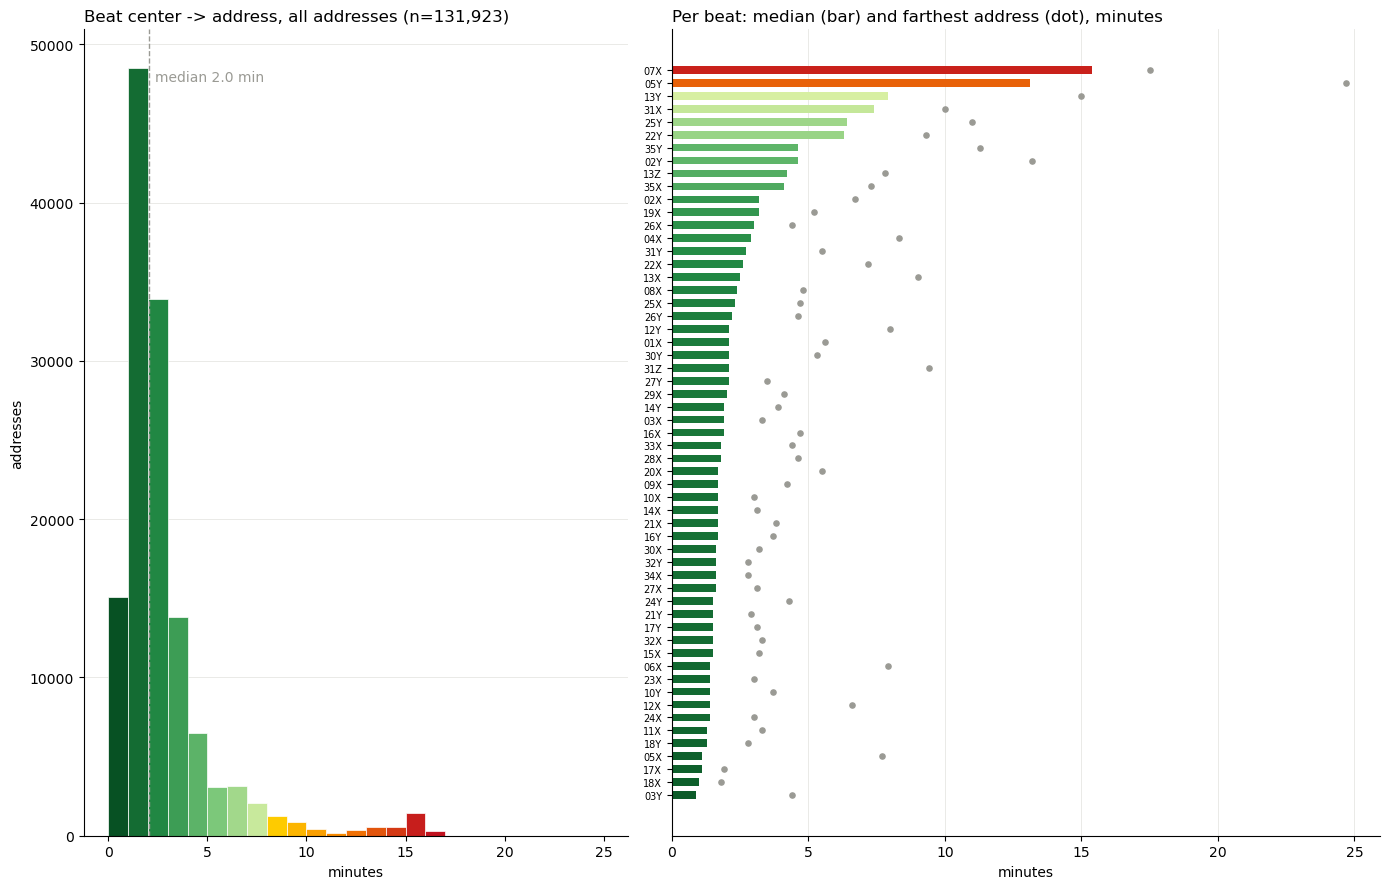

In [9]:
# 8) Distribution of beat center -> address times. Colour scale: greens to 8 min, yellow to red beyond.
VMAX = 16
greens = LinearSegmentedColormap.from_list("g", ["#00441b", "#238b45", "#74c476", "#d9f0a3"])(np.linspace(0, 1, 128))
hots = LinearSegmentedColormap.from_list("h", ["#ffd600", "#f77f00", "#c1121f"])(np.linspace(0, 1, 128))
CMAP = ListedColormap(np.vstack([greens, hots]), name="mins")
CMAP.set_over("#c1121f")
NORM = Normalize(vmin=0, vmax=VMAX)
GREY = "#9a9a94"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 9), gridspec_kw={"width_ratios": [1, 1.3]})
counts, bin_edges, patches = ax1.hist(results["minutes"].dropna(), bins=np.arange(0, results["minutes"].max() + 1, 1),
                                      edgecolor="white", linewidth=.5)
for p, left in zip(patches, bin_edges[:-1]):
    p.set_facecolor(CMAP(NORM(left + .5)))
med = results["minutes"].median()
ax1.axvline(med, color=GREY, linestyle="--", linewidth=1)
ax1.text(med + .3, ax1.get_ylim()[1] * .95, f"median {med:.1f} min", color=GREY, va="top")
ax1.set_title(f"Beat center -> address, all addresses (n={results['minutes'].notna().sum():,})", loc="left")
ax1.set_xlabel("minutes"); ax1.set_ylabel("addresses")

s = summary.sort_values("median")
y = np.arange(len(s))
ax2.barh(y, s["median"], color=[CMAP(NORM(v)) for v in s["median"]], height=.6)
ax2.scatter(s["max"], y, color=GREY, s=14, zorder=3)
ax2.set_yticks(y); ax2.set_yticklabels(s["beat"], fontsize=7)
ax2.set_title("Per beat: median (bar) and farthest address (dot), minutes", loc="left")
ax2.set_xlabel("minutes")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x" if ax is ax2 else "y", color="#e6e6e3", linewidth=.6); ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

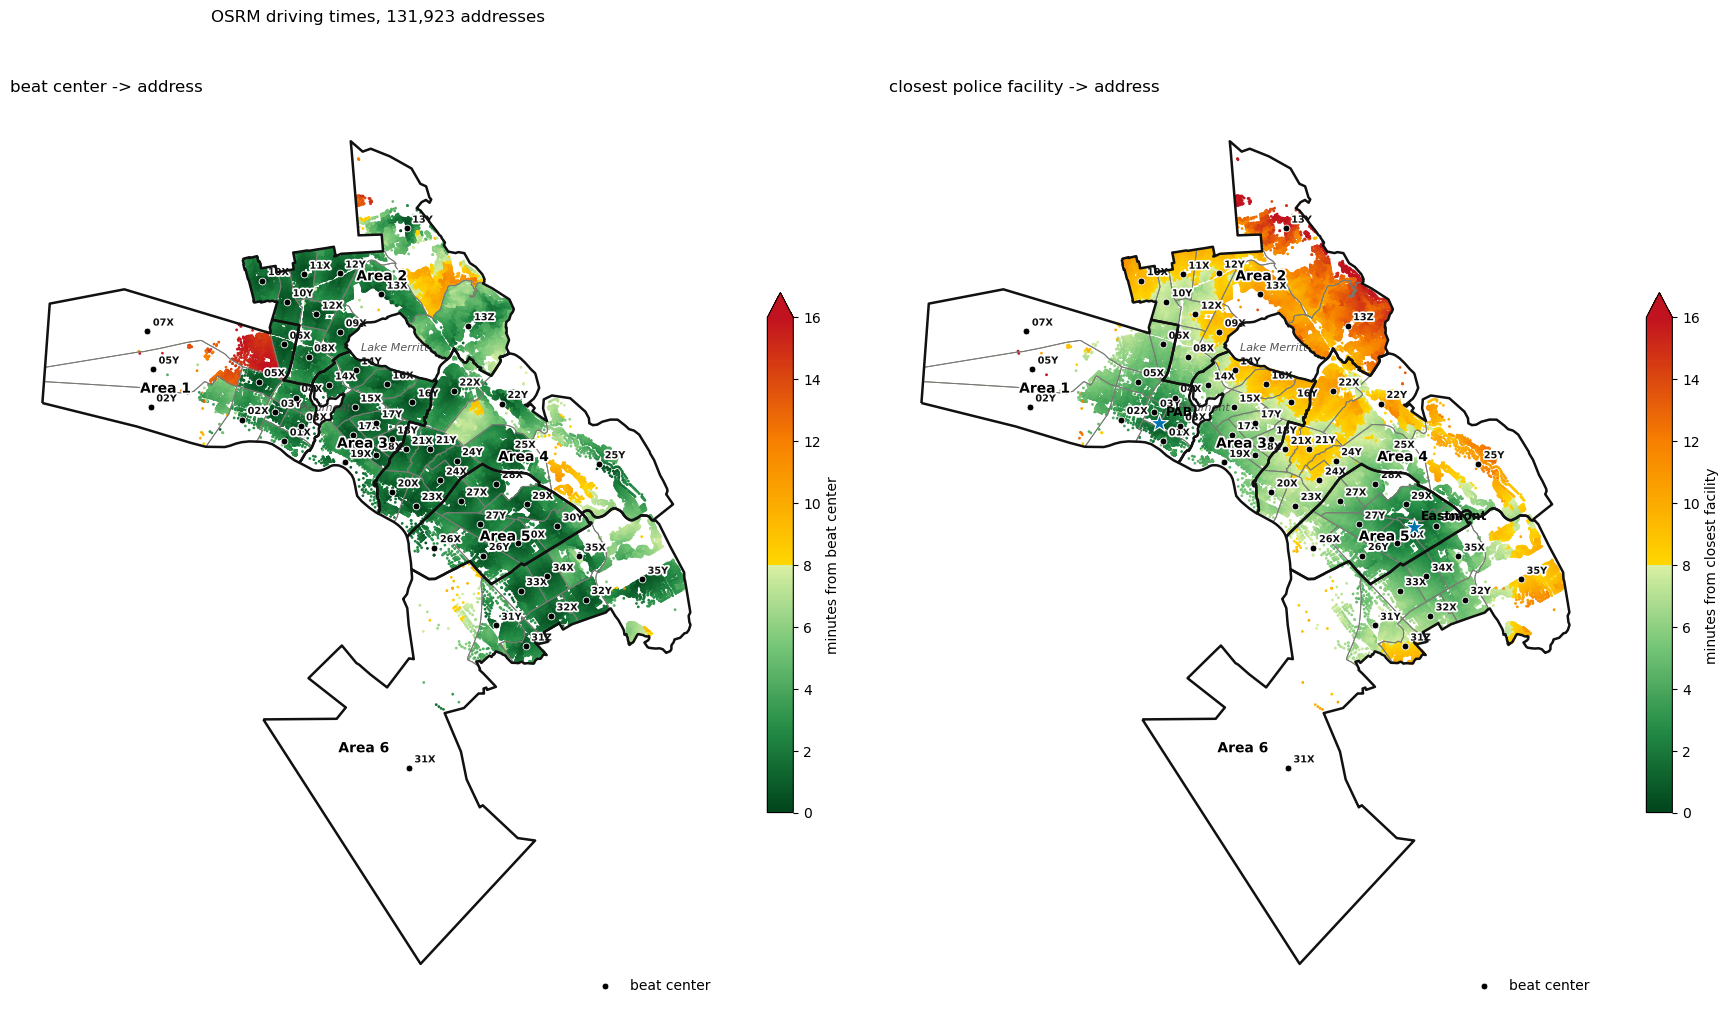

In [10]:
# 9) Maps: beat center -> address and closest facility -> address.
halo = [pe.withStroke(linewidth=2.5, foreground="white")]
closest = (facility_results.loc[facility_results.groupby(["beat", "ADDRESS", "lon", "lat"])["minutes"].idxmin()]
           .rename(columns={"minutes": "facility_minutes"}))
pts = results.merge(closest[["beat", "ADDRESS", "lon", "lat", "facility_minutes"]], on=["beat", "ADDRESS", "lon", "lat"], how="left")
pts = gpd.GeoDataFrame(pts, geometry=gpd.points_from_xy(pts["lon"], pts["lat"]), crs=4326)
# Patrol Area outlines; grow 1 m, dissolve, shrink 1 m to close sub-metre gaps between beat polygons
areas = (beats[["area", "geometry"]].to_crs(26910).assign(geometry=lambda d: d.buffer(1))
         .dissolve(by="area").assign(geometry=lambda d: d.buffer(-1)).to_crs(4326).reset_index())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 11))
for ax, column, title, label in [(ax1, "minutes", "beat center -> address", "minutes from beat center"),
                                 (ax2, "facility_minutes", "closest police facility -> address", "minutes from closest facility")]:
    beats.boundary.plot(ax=ax, color="#7a7a75", linewidth=.7)
    areas.boundary.plot(ax=ax, color="#111", linewidth=1.8, zorder=4)
    for a in areas.itertuples():
        pt = a.geometry.representative_point()
        ax.annotate(f"Area {a.area}", (pt.x, pt.y), xytext=(0, -12), textcoords="offset points", ha="center",
                    fontsize=10, fontweight="bold", path_effects=halo, zorder=6)
    pts.plot(ax=ax, column=column, cmap=CMAP, norm=NORM, markersize=1,
             legend=True, legend_kwds={"label": label, "shrink": .5, "extend": "max"})
    ax.scatter(beats["center_lon"], beats["center_lat"], color="black", edgecolor="white", linewidth=.6, s=24, zorder=5, label="beat center")
    for b in beats.itertuples():
        ax.annotate(b.beat, (b.center_lon, b.center_lat), xytext=(4, 4), textcoords="offset points",
                    fontsize=7, color="#111", fontweight="bold", path_effects=halo)
    for e in enclaves.itertuples():
        c = e.geometry.centroid
        ax.annotate(e.label, (c.x, c.y), ha="center", va="center", fontsize=8, color="#555", style="italic")
    ax.set_title(title, loc="left")
    ax.set_aspect(1 / np.cos(np.radians(37.8)))
    ax.set_axis_off()
    ax.legend(loc="lower right", frameon=False)
for f in facilities.itertuples():
    ax2.scatter(f.lon, f.lat, marker="*", s=180, color="#0072b2", edgecolor="white", linewidth=.8, zorder=6)
    ax2.annotate(f.facility, (f.lon, f.lat), xytext=(5, 5), textcoords="offset points", fontsize=9, fontweight="bold")
fig.suptitle(f"OSRM driving times, {len(pts):,} addresses", x=.12, ha="left")
plt.tight_layout()
plt.show()

In [11]:
# 10) Mapbox Directions (historical time-of-day traffic) vs observed 2026 travel (en route -> arrival), 500 sampled calls.
#     Rows from Apr-May 2026 are dropped: officer timestamps in those months are misaligned in the source export.
sample = pd.read_parquet(CACHE / "mapbox_vs_cad_sample.parquet")
sample = sample[~sample["FirstUnitEnrouteTime"].dt.month.isin([4, 5])].copy()

def mapbox_minutes(row, token):
    coords = f"{row.center_lon:.6f},{row.center_lat:.6f};{row.lon:.6f},{row.lat:.6f}"
    r = requests.get(f"https://api.mapbox.com/directions/v5/mapbox/driving/{coords}",
                     params={"access_token": token, "depart_at": row.FirstUnitEnrouteTime.strftime("%Y-%m-%dT%H:%M"),
                             "overview": "false"}, timeout=30)
    r.raise_for_status()
    time.sleep(0.25)                          # rate limit: 300 requests/min
    return r.json()["routes"][0]["duration"] / 60

if RERUN_MAPBOX:
    import os
    sample["mapbox_min"] = [mapbox_minutes(r, os.environ["MAPBOX_TOKEN"]) for r in sample.itertuples()]
sample["diff_min"] = sample["mapbox_min"] - sample["drive_min"]
print(f"{len(sample)} calls | median observed {sample['drive_min'].median():.1f} min | median Mapbox {sample['mapbox_min'].median():.1f} min | "
      f"median difference {sample['diff_min'].median():+.1f} min")

354 calls | median observed 8.3 min | median Mapbox 2.7 min | median difference -5.3 min


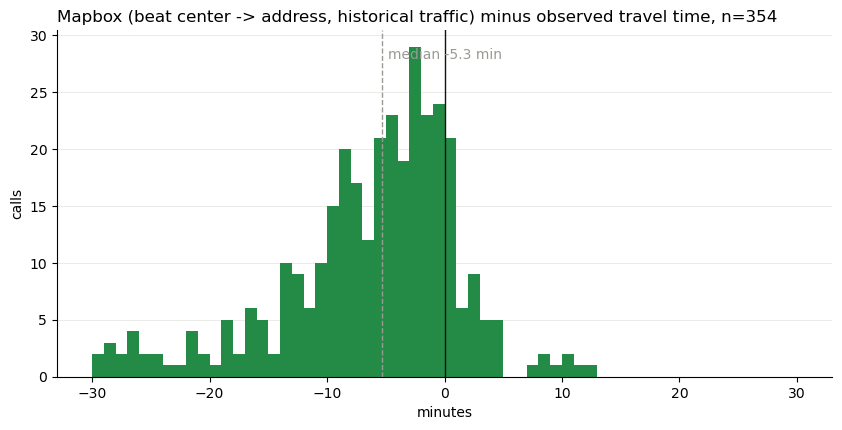

In [12]:
# 11) Mapbox estimate minus observed travel (negative = officer faster than the estimate).
d = sample["diff_min"]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(d, bins=60, range=(-30, 30), color="#238b45")
ax.axvline(0, color="#111", linewidth=1)
ax.axvline(d.median(), color=GREY, linestyle="--", linewidth=1)
ax.text(d.median() + .5, ax.get_ylim()[1] * .95, f"median {d.median():+.1f} min", color=GREY, va="top")
ax.set_title(f"Mapbox (beat center -> address, historical traffic) minus observed travel time, n={len(d):,}", loc="left")
ax.set_xlabel("minutes"); ax.set_ylabel("calls")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e6e3", linewidth=.6); ax.set_axisbelow(True)
plt.show()

## Notes

- OSRM times are free-flow civilian driving on OpenStreetMap roads, not police response.
- CAD has no unit ID or unit location, so the responding car's starting point is unknown. Patrol-car GPS is installed but not activated (audit p.63).
- Coordinate order: OSRM and GeoJSON use lon,lat. OSRM durations are in seconds.